# Análise Exploratória - Dados NPS

## 1. Importação das bibliotecas

In [40]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

### 1.1 Definindo identidade visual

In [41]:
AZUL = "#17365D"
VERDE = "#26A69A"
CINZA = "#65758B"

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=[AZUL, VERDE]
)

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "grid.alpha": 0.2,
    "axes.spines.top": False,
    "axes.spines.right": False
})

## 2. Carregamento e estrutura dos dados

In [42]:
dados = pd.read_csv("../data/raw/desafio_nps_fase_1.csv")

In [43]:
dados.head(10)

,customer_id,customer_age,customer_region,customer_tenure_months,order_id,order_value,items_quantity,discount_value,payment_installments,delivery_time_days,delivery_delay_days,freight_value,delivery_attempts,customer_service_contacts,resolution_time_days,nps_score,repeat_purchase_30d,complaints_count,csat_internal_score
0,1,63,Nordeste,14,50001,139.73,4,39.35,4,2,2,55.53,3,0,4,6.9,0,3,6.5
1,2,20,Sul,1,50002,458.95,2,9.51,10,6,4,28.23,3,0,10,2.4,0,3,0.0
2,3,46,Nordeste,111,50003,507.06,5,42.82,6,6,1,40.99,1,4,5,4.8,0,7,1.5
3,4,52,Centro-Oeste,117,50004,302.19,2,19.58,9,5,2,35.24,3,1,11,5.9,0,4,0.3
4,5,56,Norte,50,50005,253.06,1,29.37,11,13,1,39.32,1,1,0,6.1,0,3,7.9
5,6,35,Sudeste,75,50006,568.76,6,36.58,3,4,5,41.82,2,2,3,0.9,0,5,1.5
6,7,37,Sudeste,68,50007,41.29,3,99.62,6,8,3,35.83,3,3,4,1.4,0,6,0.6
7,8,60,Sul,37,50008,428.76,4,29.54,10,11,5,44.50,1,0,2,0.0,0,2,4.1
8,9,40,Sul,60,50009,121.56,3,91.95,6,6,3,24.88,2,1,9,6.2,0,3,0.8
9,10,51,Sudeste,70,50010,411.01,6,37.47,3,9,2,30.59,1,0,7,2.7,0,2,4.2


In [44]:
print(f"O conjunto de dados possui {dados.shape[0]} linhas e {dados.shape[1]} colunas")

O conjunto de dados possui 2500 linhas e 19 colunas


In [45]:
dados.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                2500 non-null   int64  
 1   customer_age               2500 non-null   int64  
 2   customer_region            2500 non-null   str    
 3   customer_tenure_months     2500 non-null   int64  
 4   order_id                   2500 non-null   int64  
 5   order_value                2500 non-null   float64
 6   items_quantity             2500 non-null   int64  
 7   discount_value             2500 non-null   float64
 8   payment_installments       2500 non-null   int64  
 9   delivery_time_days         2500 non-null   int64  
 10  delivery_delay_days        2500 non-null   int64  
 11  freight_value              2500 non-null   float64
 12  delivery_attempts          2500 non-null   int64  
 13  customer_service_contacts  2500 non-null   int64  
 14  res

## 3. Qualidade dos dados

### 3.1 Valores ausentes e vazios

In [46]:
dados.isnull().sum()

customer_id                  0
customer_age                 0
customer_region              0
customer_tenure_months       0
order_id                     0
order_value                  0
items_quantity               0
discount_value               0
payment_installments         0
delivery_time_days           0
delivery_delay_days          0
freight_value                0
delivery_attempts            0
customer_service_contacts    0
resolution_time_days         0
nps_score                    0
repeat_purchase_30d          0
complaints_count             0
csat_internal_score          0
dtype: int64

In [47]:
print("Valores nulos:", dados.isna().sum().sum())

# Valores vazios, espaços em branco ou textos que indicam ausência de informação na coluna customer_region
marcadores = ["", "na", "n/a", "null", "none", "nan"]

print("Valores vazios ou ausentes em texto:",
      dados["customer_region"].str.strip().str.lower().isin(marcadores).sum())

Valores nulos: 0
Valores vazios ou ausentes em texto: 0


### 3.2 Registros duplicados

In [48]:
print("Linhas duplicadas:", dados.duplicated().sum())

print("Pedidos duplicados:", dados["order_id"].duplicated().sum())

Linhas duplicadas: 0
Pedidos duplicados: 0


### 3.3 Consistência e limites dos valores

In [49]:
# Verificando se existe valores fora do range esperado
print("NPS inválido:", ((dados["nps_score"] < 0) | (dados["nps_score"] > 10)).sum())

print("Idade inválida:", (dados["customer_age"] <= 0).sum())

print("Tempo de relacionamento negativo:", (dados["customer_tenure_months"] < 0).sum())

print("Valor do pedido inválido:", (dados["order_value"] < 0).sum())

print("Quantidade de itens inválida:", (dados["items_quantity"] <= 0).sum())

print("Desconto negativo:", (dados["discount_value"] < 0).sum())

print("Tempo de entrega negativo:", (dados["delivery_time_days"] < 0).sum())

print("Atraso negativo:", (dados["delivery_delay_days"] < 0).sum())

print("Quantidade de reclamações negativa:", (dados["complaints_count"] < 0).sum())

print("Frete negativo:", (dados["freight_value"] < 0).sum())

print("Parcelas inválidas:", (dados["payment_installments"] < 1).sum())

print("Tentativas de entrega inválidas:", (dados["delivery_attempts"] < 1).sum())

print("Contatos negativos:", (dados["customer_service_contacts"] < 0).sum())

print("Tempo de resolução negativo:", (dados["resolution_time_days"] < 0).sum())

print("Recompra inválida:", ((dados["repeat_purchase_30d"] != 0) & (dados["repeat_purchase_30d"] != 1)).sum())

NPS inválido: 0
Idade inválida: 0
Tempo de relacionamento negativo: 0
Valor do pedido inválido: 0
Quantidade de itens inválida: 0
Desconto negativo: 0
Tempo de entrega negativo: 0
Atraso negativo: 0
Quantidade de reclamações negativa: 0
Frete negativo: 0
Parcelas inválidas: 0
Tentativas de entrega inválidas: 0
Contatos negativos: 0
Tempo de resolução negativo: 0
Recompra inválida: 0


In [50]:
# Verificação de notas de NPS com casas decimais
nps_com_decimais = (dados["nps_score"] % 1 != 0).sum()

print(f"NPS com valores decimais:{nps_com_decimais}")

print(f"Percentual de NPS com valores decimais: {nps_com_decimais / len(dados) * 100:.2f}%")

NPS com valores decimais:2075
Percentual de NPS com valores decimais: 83.00%


### 3.4 Validação das categorias

In [51]:
dados["customer_region"].value_counts()

customer_region
Sul             521
Sudeste         520
Norte           506
Nordeste        485
Centro-Oeste    468
Name: count, dtype: int64

### 3.5 Resumo - Qualidade dos dados

A base contém 2.500 registros e 19 variáveis.

Nas verificações, não foram encontrados valores nulos, textos indicando ausência de informação ou registros duplicados.

As variáveis numéricas estão dentro dos limites básicos definidos, e as cinco regiões brasileiras estão representadas corretamente.

Considerando essas validações, não foi necessário realizar nenhum tratamento nos dados nesta etapa.

**Observação:** Tradicionalmente, o NPS é coletado por meio de notas inteiras de 0 a 10. Entretanto, como 83% dos registros apresentam notas decimais, seguiremos com a análise preservando os valores originais, considerando essa característica como uma limitação da base, já que o enunciado não esclarece a origem dessas notas.

## 4. Estatística descritiva

In [52]:

dados.describe().T

,count,mean,std,min,25%,50%,75%,max
customer_id,2500.0,1250.500000,721.832160,1.00,625.7500,1250.500,1875.2500,2500.00
customer_age,2500.0,43.396000,14.888487,18.00,31.0000,43.000,56.0000,69.00
customer_tenure_months,2500.0,61.322400,34.478729,1.00,31.0000,62.000,91.0000,119.00
order_id,2500.0,51250.500000,721.832160,50001.00,50625.7500,51250.500,51875.2500,52500.00
order_value,2500.0,434.259740,289.772497,7.76,220.2450,375.515,577.2900,1983.81
items_quantity,2500.0,3.470800,1.687331,1.00,2.0000,3.000,5.0000,6.00
discount_value,2500.0,29.745620,29.225603,0.02,8.8850,20.935,40.8325,230.33
payment_installments,2500.0,6.004000,3.159743,1.00,3.0000,6.000,9.0000,11.00
delivery_time_days,2500.0,8.022000,3.770411,2.00,5.0000,8.000,11.0000,14.00
delivery_delay_days,2500.0,2.187200,1.454442,0.00,1.0000,2.000,3.0000,8.00


A análise não apresentou valores mínimos ou máximos claramente incompatíveis com o contexto dos dados.

Alguns indicadores chamaram a atenção:

- A nota média de satisfação é de 4,38, indicando avaliações relativamente baixas.
- A recompra em até 30 dias permanece em zero (sem recompra) até o 3º quartil.
- A quantidade média de reclamações é de 4,15 por registro.
- O atraso médio nas entregas é de 2,19 dias, com pelo menos 75% dos registros apresentando atrasos de 1 dia ou mais.

## 5. Análise da satisfação dos clientes

### 5.1 Distribuição das notas
Como estão distribuídas as notas de NPS dos clientes? 

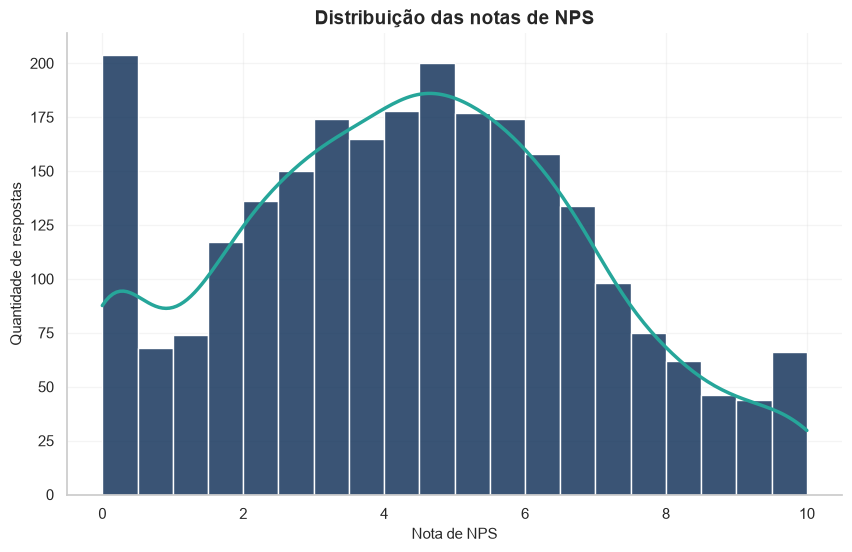

In [53]:
plt.figure(figsize=(10,6))

ax = sns.histplot(
    data=dados,
    x="nps_score",
    bins=20,
    kde=True,
    color=AZUL,
    edgecolor="white",
    alpha=0.85,
    line_kws={"linewidth": 2.5}
)

ax.lines[0].set_color(VERDE)

plt.title("Distribuição das notas de NPS")
plt.xlabel("Nota de NPS")
plt.ylabel("Quantidade de respostas")

plt.show()

**Análise da distribuição das notas**

A maior concentração está entre as notas 3 e 6, com o pico próximo de 5.

A concentração de notas próximas de zero chama atenção,enquanto notas mais altas tem uma menor frequência.

A distribuição indica uma tendência de avaliações mais baixas, reforçando a necessidade de investigar quais são os fatores associados a insatisfação.

### 5.2 Classificação dos clientes por NPS

Para analisar a proporção dos clientes detratores, neutros e promotores, vamos classificar as notas de NPS em três categorias.

![Classificação dos clientes por NPS](../images/classificacao_nps.jpg)

In [54]:
#Classificando as notas de NPS

def classificar_nps(nota):
    if nota < 7:
        return "Detrator"
    elif nota < 9:
        return "Neutro"
    else:
        return "Promotor"

dados["nps_classificacao"] = dados["nps_score"].apply(classificar_nps)

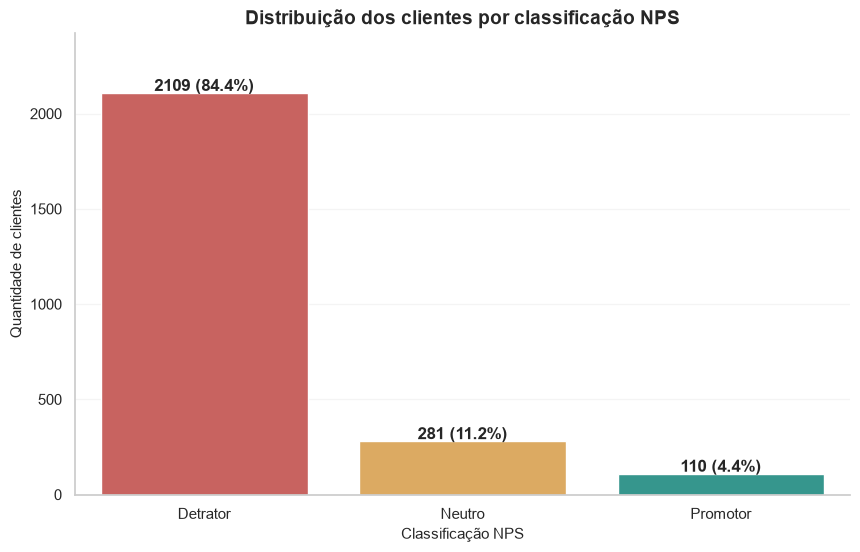

In [55]:
# Quantidade de clientes por classificação
ordem = ["Detrator", "Neutro", "Promotor"]
contagem = dados["nps_classificacao"].value_counts().reindex(ordem)

# Cores das classificações
cores = ["#D9534F", "#F0AD4E", "#26A69A"]


ax = sns.barplot(
    x=contagem.index,
    y=contagem.values,
    hue=contagem.index,
    palette=cores,
    legend=False
)

# Quantidade e percentual em cada barra
for i, quantidade in enumerate(contagem):
    percentual = quantidade / len(dados) * 100
    ax.text(i, quantidade + 10, f"{quantidade} ({percentual:.1f}%)",
            ha="center", fontweight="bold")

plt.title("Distribuição dos clientes por classificação NPS")
plt.xlabel("Classificação NPS")
plt.ylabel("Quantidade de clientes")
plt.ylim(0, contagem.max() * 1.15)

plt.show()

### 5.3 Cálculo do NPS geral

O Net Promoter Score (NPS) é calculado pela diferença entre o percentual de clientes promotores e detratores, resultando em um indicador que varia de -100 a 100.

$$
NPS = \% \text{Promotores} - \% \text{Detratores}
$$

Como referência para interpretação do resultado, utilizaremos as seguintes faixas:

| Faixa de NPS | Classificação |
|---|---|
| -100 a -1 | Zona Crítica |
| 0 a 49 | Zona de Aperfeiçoamento |
| 50 a 74 | Zona de Qualidade |
| 75 a 100 | Zona de Excelência |

Essas faixas são uma referência gerencial, e não uma classificação universal do NPS.

In [56]:
# Cálculo do NPS geral
percentual_detratores = contagem["Detrator"] / len(dados) * 100
percentual_promotores = contagem["Promotor"] / len(dados) * 100

nps_geral = percentual_promotores - percentual_detratores

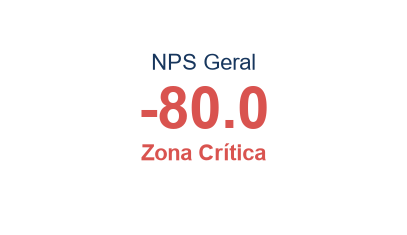

In [57]:
# Cartão para ênfase do NPS geral
plt.figure(figsize=(5, 2.8))

plt.text(
    0.5, 0.72, "NPS Geral",
    fontsize=16,
    ha="center",
    color=AZUL
)

plt.text(
    0.5, 0.45, f"{nps_geral:.1f}",
    fontsize=42,
    fontweight="bold",
    ha="center",
    color="#D9534F"
)

plt.text(
    0.5, 0.3, "Zona Crítica",
    fontsize=16,
    fontweight="bold",
    ha="center",
    color="#D9534F"
)

plt.xlim(0, 1)
plt.ylim(0, 1)
plt.axis("off")

plt.show()

### 5.4 Resumo da análise do NPS

A análise mostrou que 84,4% dos clientes são detratores, 11,2% neutros e apenas 4,4% promotores.

O NPS geral calculado foi de -80 pontos, enquadrando a empresa na Zona Crítica, conforme a classificação adotada no projeto.

Os resultados indicam um cenário de insatisfação elevada, sendo necessário investigar quais fatores estão associados às avaliações negativas.

## 6. Análise do perfil dos clientes

Nesta etapa, vamos investigar se características como região, idade e tempo de relacionamento com a empresa apresentam diferenças nos níveis de satisfação.

### 6.1 NPS por região

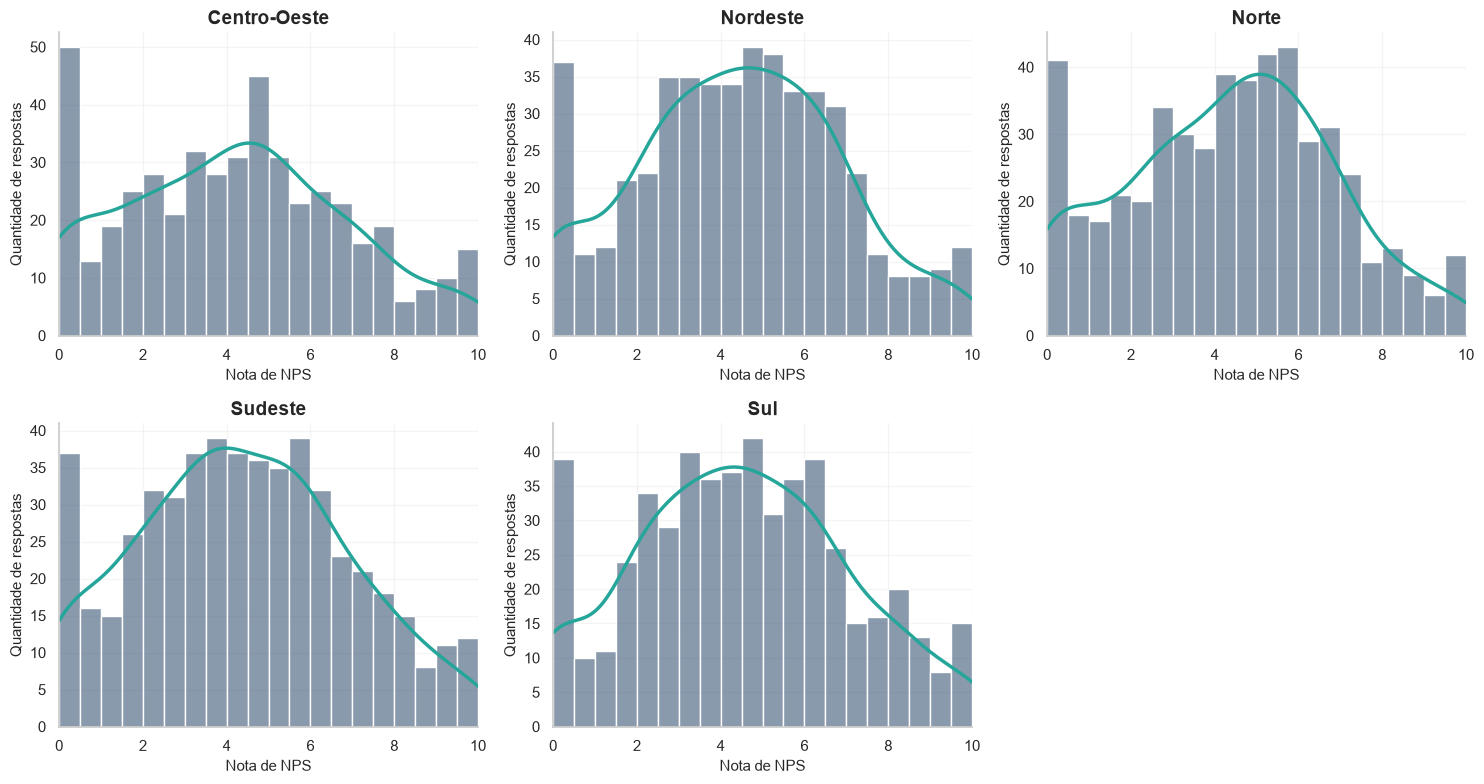

In [58]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

regioes = sorted(dados["customer_region"].unique())

for ax, regiao in zip(axes.flat, regioes):
    sns.histplot(
        data=dados[dados["customer_region"] == regiao],
        x="nps_score",
        bins=20,
        binrange=(0, 10),
        kde=True,
        color=AZUL,
        edgecolor="white",
        line_kws={"linewidth": 2.5},
        ax=ax
    )

    # Alterar a cor da curva KDE
    ax.lines[0].set_color(VERDE)

    ax.set_title(regiao)
    ax.set_xlabel("Nota de NPS")
    ax.set_ylabel("Quantidade de respostas")
    ax.set_xlim(0, 10)

# Ocultar gráfico não utilizado
axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

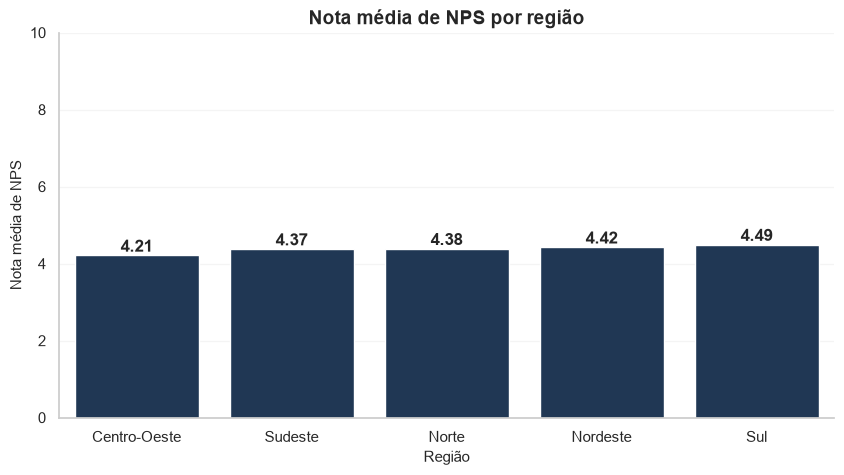

In [59]:
# Nota média de NPS por região
nps_regiao = dados.groupby("customer_region")["nps_score"].mean().sort_values()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=nps_regiao.index,
    y=nps_regiao.values,
    color=AZUL
)

for i, nota in enumerate(nps_regiao):
    ax.text(i, nota + 0.1, f"{nota:.2f}",
            ha="center", fontweight="bold")

plt.title("Nota média de NPS por região")
plt.xlabel("Região")
plt.ylabel("Nota média de NPS")
plt.ylim(0, 10)

plt.show()

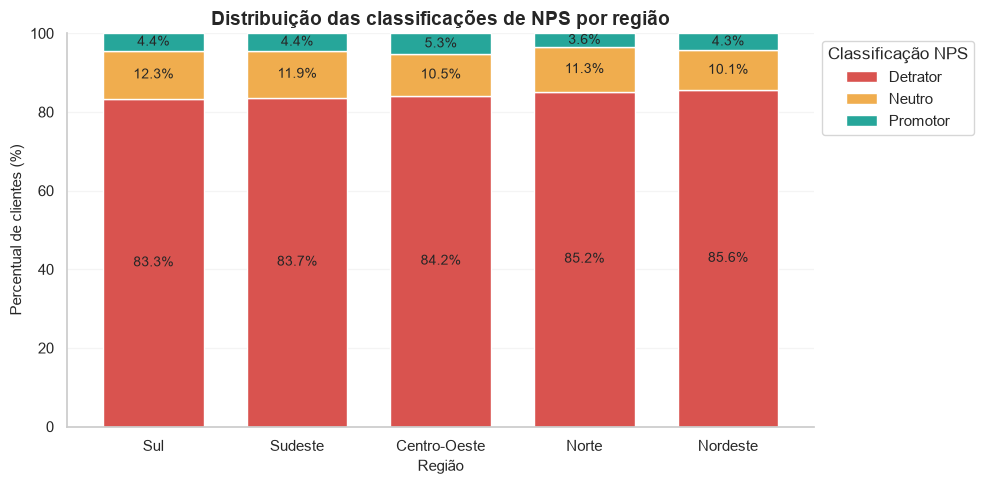

In [60]:
# Percentual de cada classificação por região
nps_regiao = pd.crosstab(
    dados["customer_region"],
    dados["nps_classificacao"],
    normalize="index"
) * 100

# Ordenar classificações e regiões
nps_regiao = nps_regiao[["Detrator", "Neutro", "Promotor"]]
nps_regiao = nps_regiao.sort_values("Detrator")

# Gráfico de barras empilhadas
ax = nps_regiao.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["#D9534F", "#F0AD4E", "#26A69A"],
    width=0.7
)

# Exibir percentuais em cada parte das barras
for barras in ax.containers:
    ax.bar_label(
        barras,
        fmt="%.1f%%",
        label_type="center",
        fontsize=10
    )

plt.title("Distribuição das classificações de NPS por região")
plt.xlabel("Região")
plt.ylabel("Percentual de clientes (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Classificação NPS", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

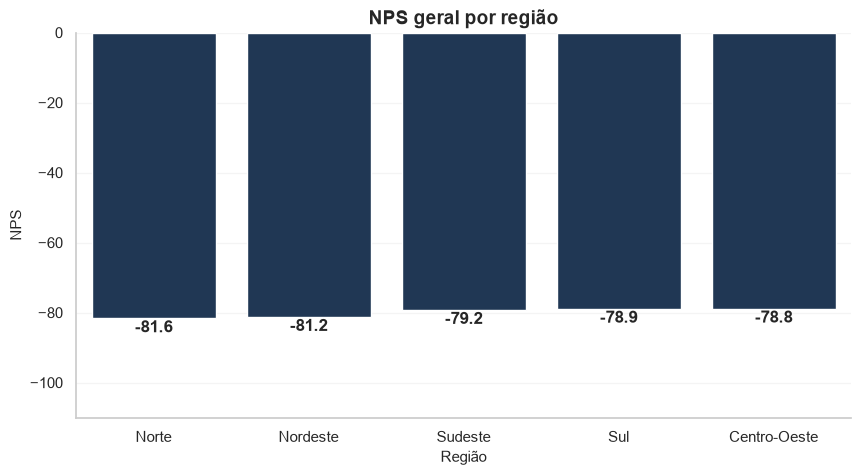

In [61]:
# Calcular NPS por região
nps_regiao["NPS"] = nps_regiao["Promotor"] - nps_regiao["Detrator"]

# Ordenar as regiões pelo NPS
nps_regiao = nps_regiao.sort_values("NPS")

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=nps_regiao.index,
    y=nps_regiao["NPS"],
    color=AZUL
)

# Exibir o NPS em cada barra
for i, valor in enumerate(nps_regiao["NPS"]):
    ax.text(
        i, valor - 4,
        f"{valor:.1f}",
        ha="center",
        fontweight="bold"
    )

plt.title("NPS geral por região")
plt.xlabel("Região")
plt.ylabel("NPS")
plt.ylim(-110, 0)

plt.show()

**Resumo da análise por região**

As cinco regiões apresentaram distribuições de notas semelhantes, com maior concentração de avaliações entre 3 e 6.

As notas médias variam de 4,21 a 4,49, enquanto os percentuais de detratores ficam entre 83,3% e 85,6%.

O NPS geral por região também apresentou pouca variação, entre -81,6 no Norte e -78,8 no Centro-Oeste, mantendo todas as regiões na Zona Crítica.

Os resultados indicam que a insatisfação está presente em todas as regiões, sem diferenças expressivas que justifiquem priorizar uma região específica neste momento.

### 6.2 NPS por Idade

**Pergunta:** A satisfação dos clientes varia conforme a idade?

Para facilitar a análise, os clientes serão agrupados em cinco faixas etárias.

| Faixa etária | Idade dos clientes |
|---|---|
| 18–29 anos | De 18 a 29 anos |
| 30–39 anos | De 30 a 39 anos |
| 40–49 anos | De 40 a 49 anos |
| 50–59 anos | De 50 a 59 anos |
| 60–69 anos | De 60 a 69 anos |

In [62]:
# Criar faixas etárias
dados["faixa_etaria"] = pd.cut(
    dados["customer_age"],
    bins=[17, 29, 39, 49, 59, 69],
    labels=["18-29", "30-39", "40-49", "50-59", "60-69"]
)

# Distribuição dos clientes por faixa etária
print(dados["faixa_etaria"].value_counts().sort_index())

faixa_etaria
18-29    561
30-39    498
40-49    496
50-59    482
60-69    463
Name: count, dtype: int64


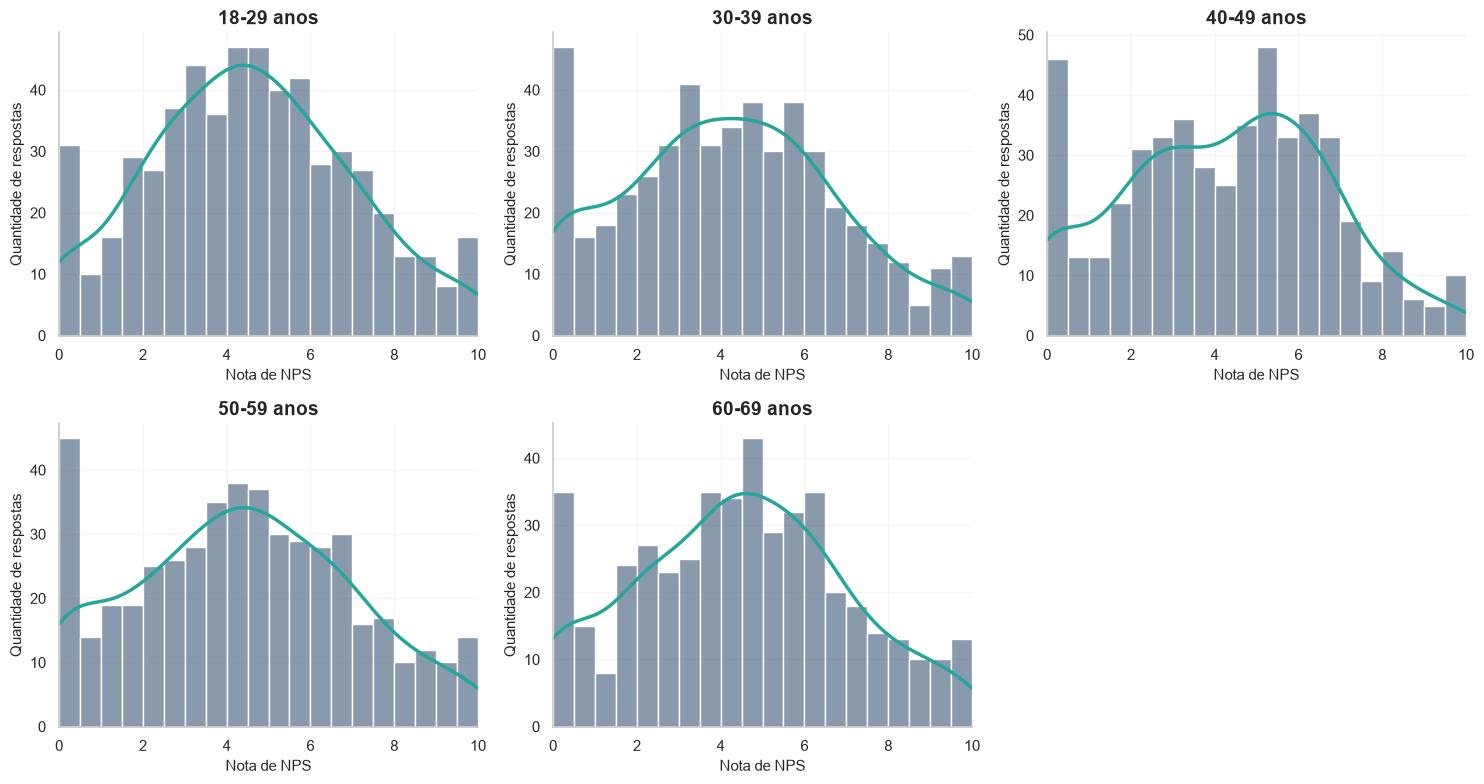

In [63]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

faixas = dados["faixa_etaria"].cat.categories

for ax, faixa in zip(axes.flat, faixas):
    sns.histplot(
        data=dados[dados["faixa_etaria"] == faixa],
        x="nps_score",
        bins=20,
        binrange=(0, 10),
        kde=True,
        color=AZUL,
        edgecolor="white",
        line_kws={"linewidth": 2.5},
        ax=ax
    )

    ax.lines[0].set_color(VERDE)

    ax.set_title(f"{faixa} anos")
    ax.set_xlabel("Nota de NPS")
    ax.set_ylabel("Quantidade de respostas")
    ax.set_xlim(0, 10)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

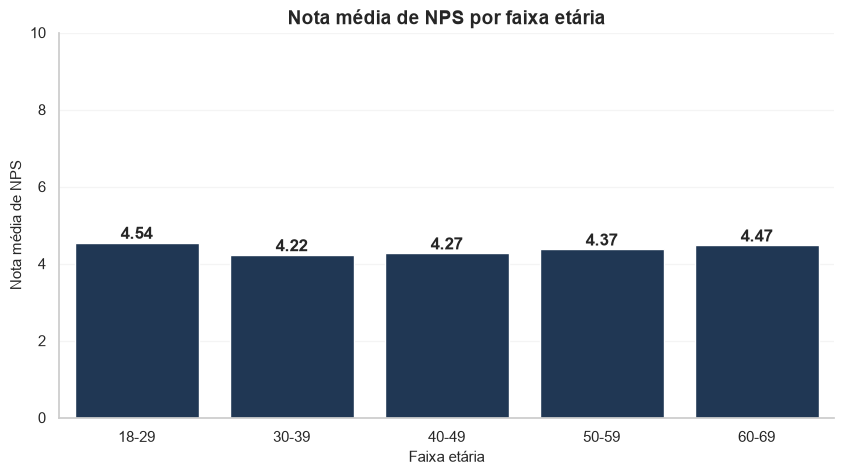

In [64]:
# Nota média de NPS por faixa etária
nps_idade = dados.groupby("faixa_etaria", observed=True)["nps_score"].mean()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=nps_idade.index,
    y=nps_idade.values,
    color=AZUL
)

# Exibir a nota média em cada barra
for i, nota in enumerate(nps_idade):
    ax.text(
        i, nota + 0.1,
        f"{nota:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.title("Nota média de NPS por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("Nota média de NPS")
plt.ylim(0, 10)

plt.show()

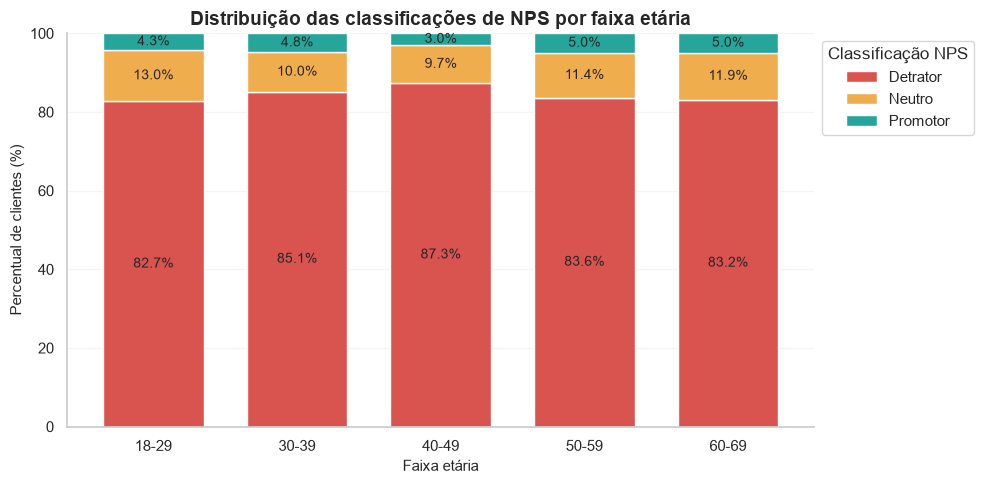

In [65]:
# Percentual de cada classificação por faixa etária
classificacao_idade = pd.crosstab(
    dados["faixa_etaria"],
    dados["nps_classificacao"],
    normalize="index"
) * 100

classificacao_idade = classificacao_idade[["Detrator", "Neutro", "Promotor"]]

# Gráfico de barras empilhadas
ax = classificacao_idade.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["#D9534F", "#F0AD4E", "#26A69A"],
    width=0.7
)

# Percentual de cada classificação
for barras in ax.containers:
    ax.bar_label(
        barras,
        fmt="%.1f%%",
        label_type="center",
        fontsize=10
    )

plt.title("Distribuição das classificações de NPS por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("Percentual de clientes (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Classificação NPS", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

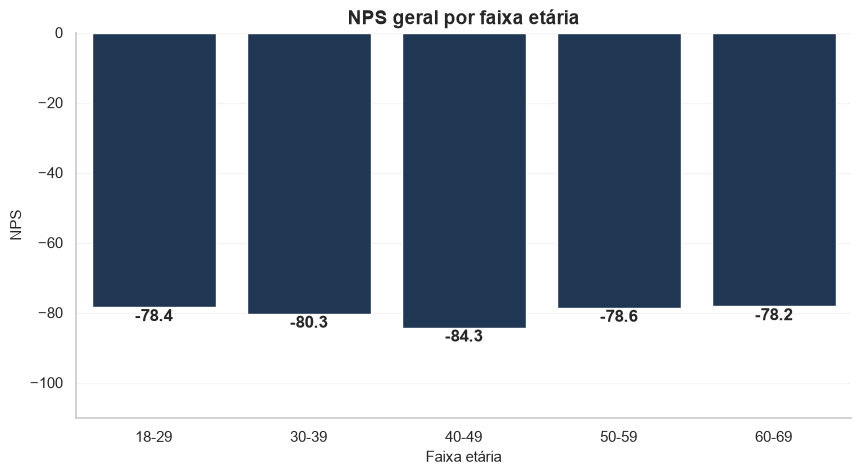

In [66]:
# Calcular NPS por faixa etária
classificacao_idade["NPS"] = (
    classificacao_idade["Promotor"] - classificacao_idade["Detrator"]
)

# Gráfico de NPS por faixa etária
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=classificacao_idade.index,
    y=classificacao_idade["NPS"],
    color=AZUL
)

for i, valor in enumerate(classificacao_idade["NPS"]):
    ax.text(
        i, valor - 4,
        f"{valor:.1f}",
        ha="center",
        fontweight="bold"
    )

plt.title("NPS geral por faixa etária")
plt.xlabel("Faixa etária")
plt.ylabel("NPS")
plt.ylim(-110, 0)

plt.show()

**Resumo da análise por idade**

As faixas etárias apresentaram distribuições de notas semelhantes, com maior concentração de avaliações entre 3 e 6.

**A faixa de 40 a 49** anos apresentou o pior resultado, portanto, requer uma atenção especial, com 87,3% de detratores e NPS de -84,3. Já a faixa de 60 a 69 anos apresentou o melhor NPS, de -78,2.

Apesar dessas diferenças, todas as faixas permanecem na Zona Crítica, indicando que a insatisfação está presente entre clientes de diferentes idades.

### 6.3 NPS por Tempo de Relacionamento

**Pergunta:** O tempo de relacionamento com a empresa está associado à satisfação dos clientes?

Para realizar essa análise, os clientes serão agrupados conforme o tempo de relacionamento com a empresa.

| Faixa | Tempo de relacionamento |
|---|---|
| Até 1 ano | 1 a 12 meses |
| 1 a 3 anos | 13 a 36 meses |
| 3 a 5 anos | 37 a 60 meses |
| 5 a 7 anos | 61 a 84 meses |
| Mais de 7 anos | 85 meses ou mais |

In [67]:
# Criar faixas de tempo de relacionamento
dados["faixa_relacionamento"] = pd.cut(
    dados["customer_tenure_months"],
    bins=[0, 12, 36, 60, 84, float("inf")],
    labels=[
        "Até 1 ano",
        "1 a 3 anos",
        "3 a 5 anos",
        "5 a 7 anos",
        "Mais de 7 anos"
    ]
)

# Quantidade de clientes por faixa
dados["faixa_relacionamento"].value_counts().sort_index()

faixa_relacionamento
Até 1 ano         242
1 a 3 anos        490
3 a 5 anos        478
5 a 7 anos        542
Mais de 7 anos    748
Name: count, dtype: int64

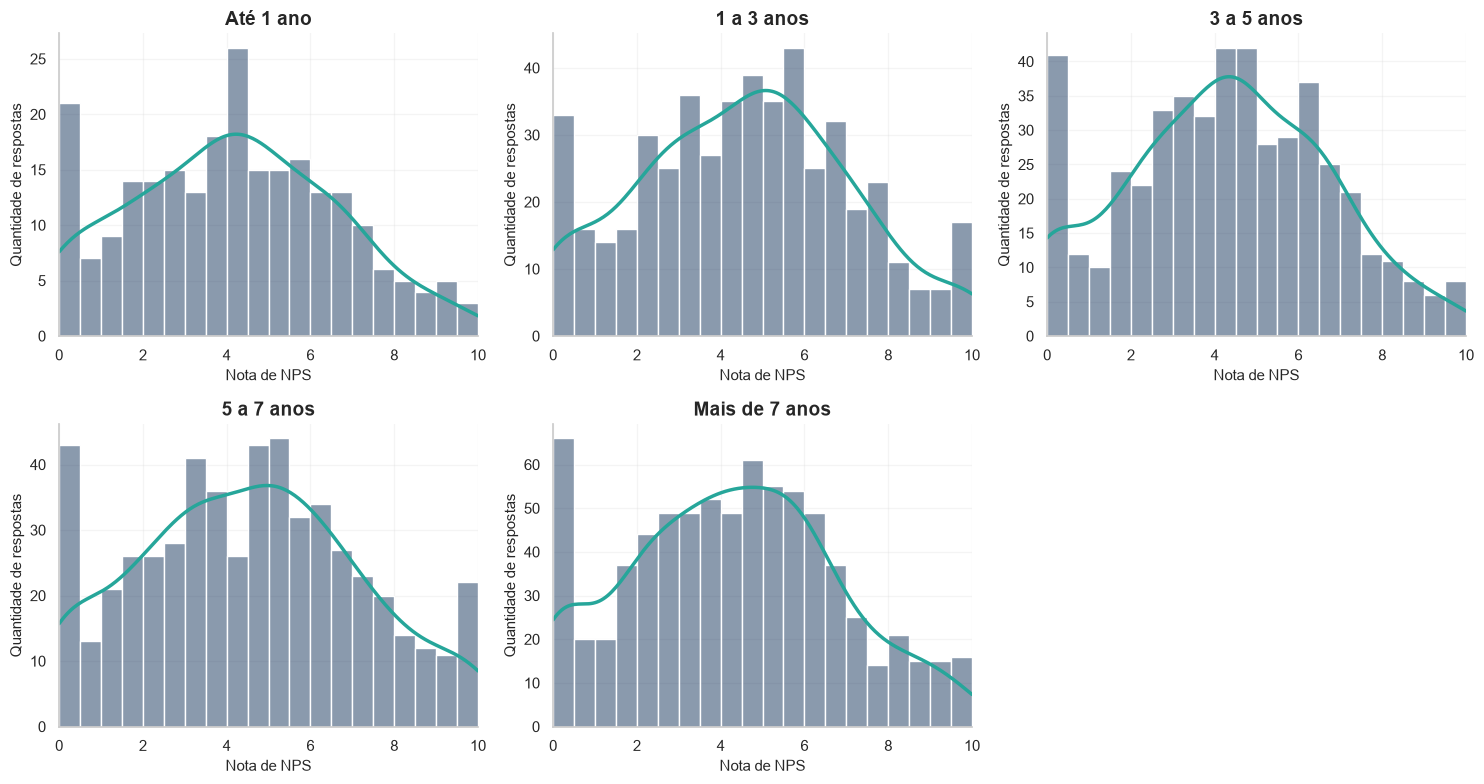

In [68]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

faixas = dados["faixa_relacionamento"].cat.categories

for ax, faixa in zip(axes.flat, faixas):
    sns.histplot(
        data=dados[dados["faixa_relacionamento"] == faixa],
        x="nps_score",
        bins=20,
        binrange=(0, 10),
        kde=True,
        color=AZUL,
        edgecolor="white",
        line_kws={"linewidth": 2.5},
        ax=ax
    )

    ax.lines[0].set_color(VERDE)

    ax.set_title(faixa)
    ax.set_xlabel("Nota de NPS")
    ax.set_ylabel("Quantidade de respostas")
    ax.set_xlim(0, 10)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

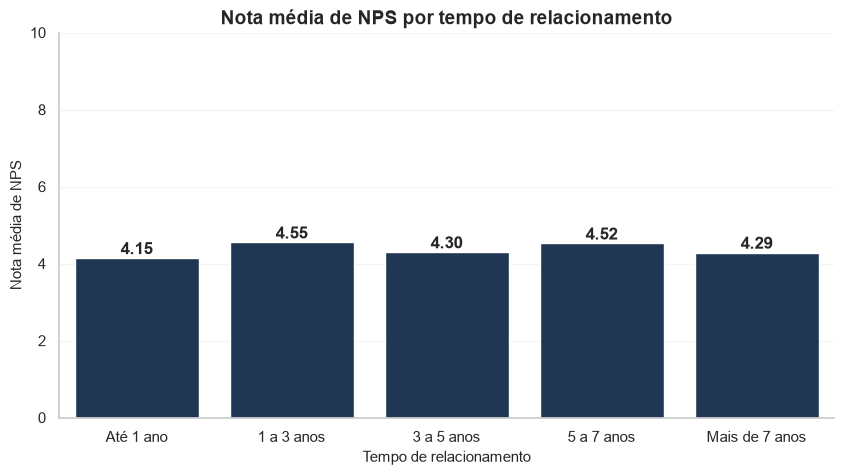

In [69]:
# Nota média de NPS por tempo de relacionamento
nps_relacionamento = dados.groupby(
    "faixa_relacionamento", observed=True
)["nps_score"].mean()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=nps_relacionamento.index,
    y=nps_relacionamento.values,
    color=AZUL
)

for i, nota in enumerate(nps_relacionamento):
    ax.text(
        i, nota + 0.1,
        f"{nota:.2f}",
        ha="center",
        fontweight="bold"
    )

plt.title("Nota média de NPS por tempo de relacionamento")
plt.xlabel("Tempo de relacionamento")
plt.ylabel("Nota média de NPS")
plt.ylim(0, 10)

plt.show()

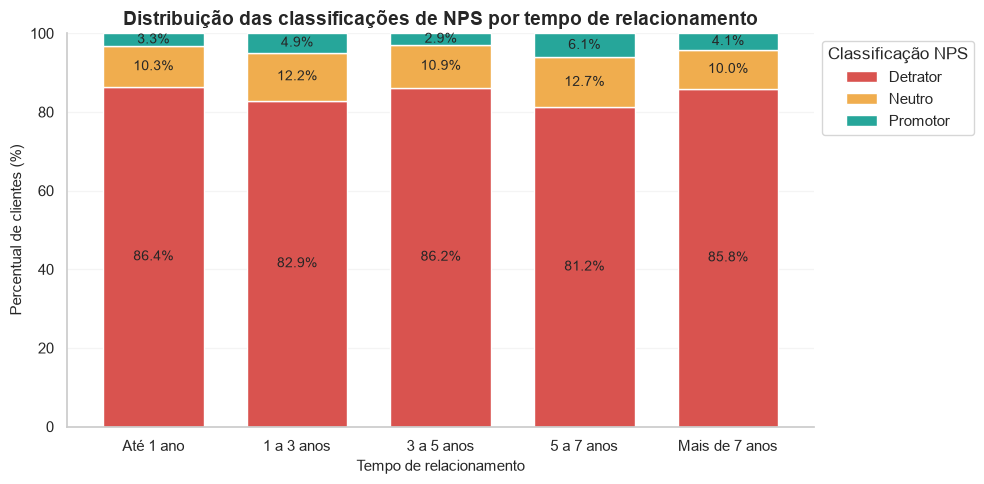

In [70]:
# Percentual de cada classificação por tempo de relacionamento
classificacao_relacionamento = pd.crosstab(
    dados["faixa_relacionamento"],
    dados["nps_classificacao"],
    normalize="index"
) * 100

classificacao_relacionamento = classificacao_relacionamento[
    ["Detrator", "Neutro", "Promotor"]
]

# Gráfico de barras empilhadas
ax = classificacao_relacionamento.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5),
    color=["#D9534F", "#F0AD4E", "#26A69A"],
    width=0.7
)

for barras in ax.containers:
    ax.bar_label(
        barras,
        fmt="%.1f%%",
        label_type="center",
        fontsize=10
    )

plt.title("Distribuição das classificações de NPS por tempo de relacionamento")
plt.xlabel("Tempo de relacionamento")
plt.ylabel("Percentual de clientes (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title="Classificação NPS", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

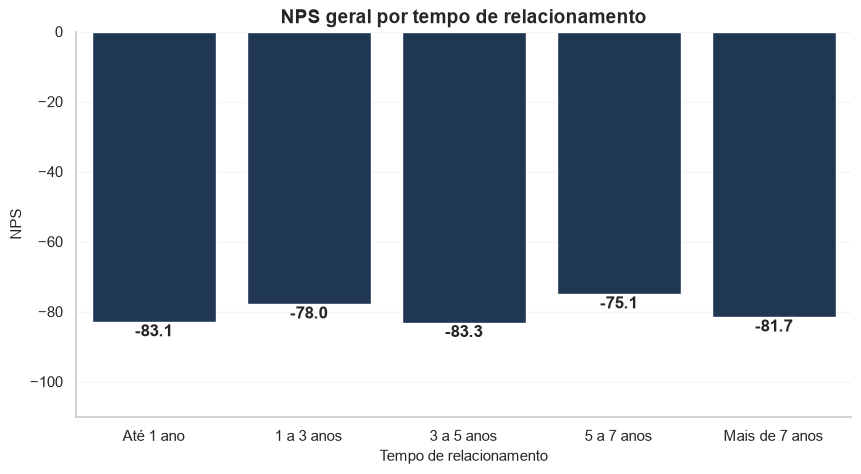

In [71]:
# Calcular NPS por tempo de relacionamento
classificacao_relacionamento["NPS"] = (
    classificacao_relacionamento["Promotor"]
    - classificacao_relacionamento["Detrator"]
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=classificacao_relacionamento.index,
    y=classificacao_relacionamento["NPS"],
    color=AZUL
)

# Exibir o NPS de cada faixa
for i, valor in enumerate(classificacao_relacionamento["NPS"]):
    ax.text(
        i, valor - 4,
        f"{valor:.1f}",
        ha="center",
        fontweight="bold"
    )

plt.title("NPS geral por tempo de relacionamento")
plt.xlabel("Tempo de relacionamento")
plt.ylabel("NPS")
plt.ylim(-110, 0)

plt.show()

**Resumo da análise por tempo de relacionamento**

Os clientes apresentaram distribuições de notas semelhantes, independentemente do tempo de relacionamento com a empresa.

A faixa de 3 a 5 anos apresentou o pior NPS (-83,3), seguida pelos clientes com até 1 ano (-83,1), sendo grupos que merecem maior atenção nas próximas análises.

Já os clientes com 5 a 7 anos apresentaram o melhor resultado, com NPS de -75,1 e o menor percentual de detratores (81,2%).

Apesar das diferenças, todos os grupos permanecem na Zona Crítica, sem uma tendência clara de melhoria na satisfação conforme aumenta o tempo de relacionamento.

## 7. Análise dos fatores operacionais

Nesta etapa, vamos investigar como os indicadores operacionais estão relacionados à satisfação dos clientes, buscando identificar fatores que possam contribuir para as avaliações negativas.

### 7.1 Análise de dispersão

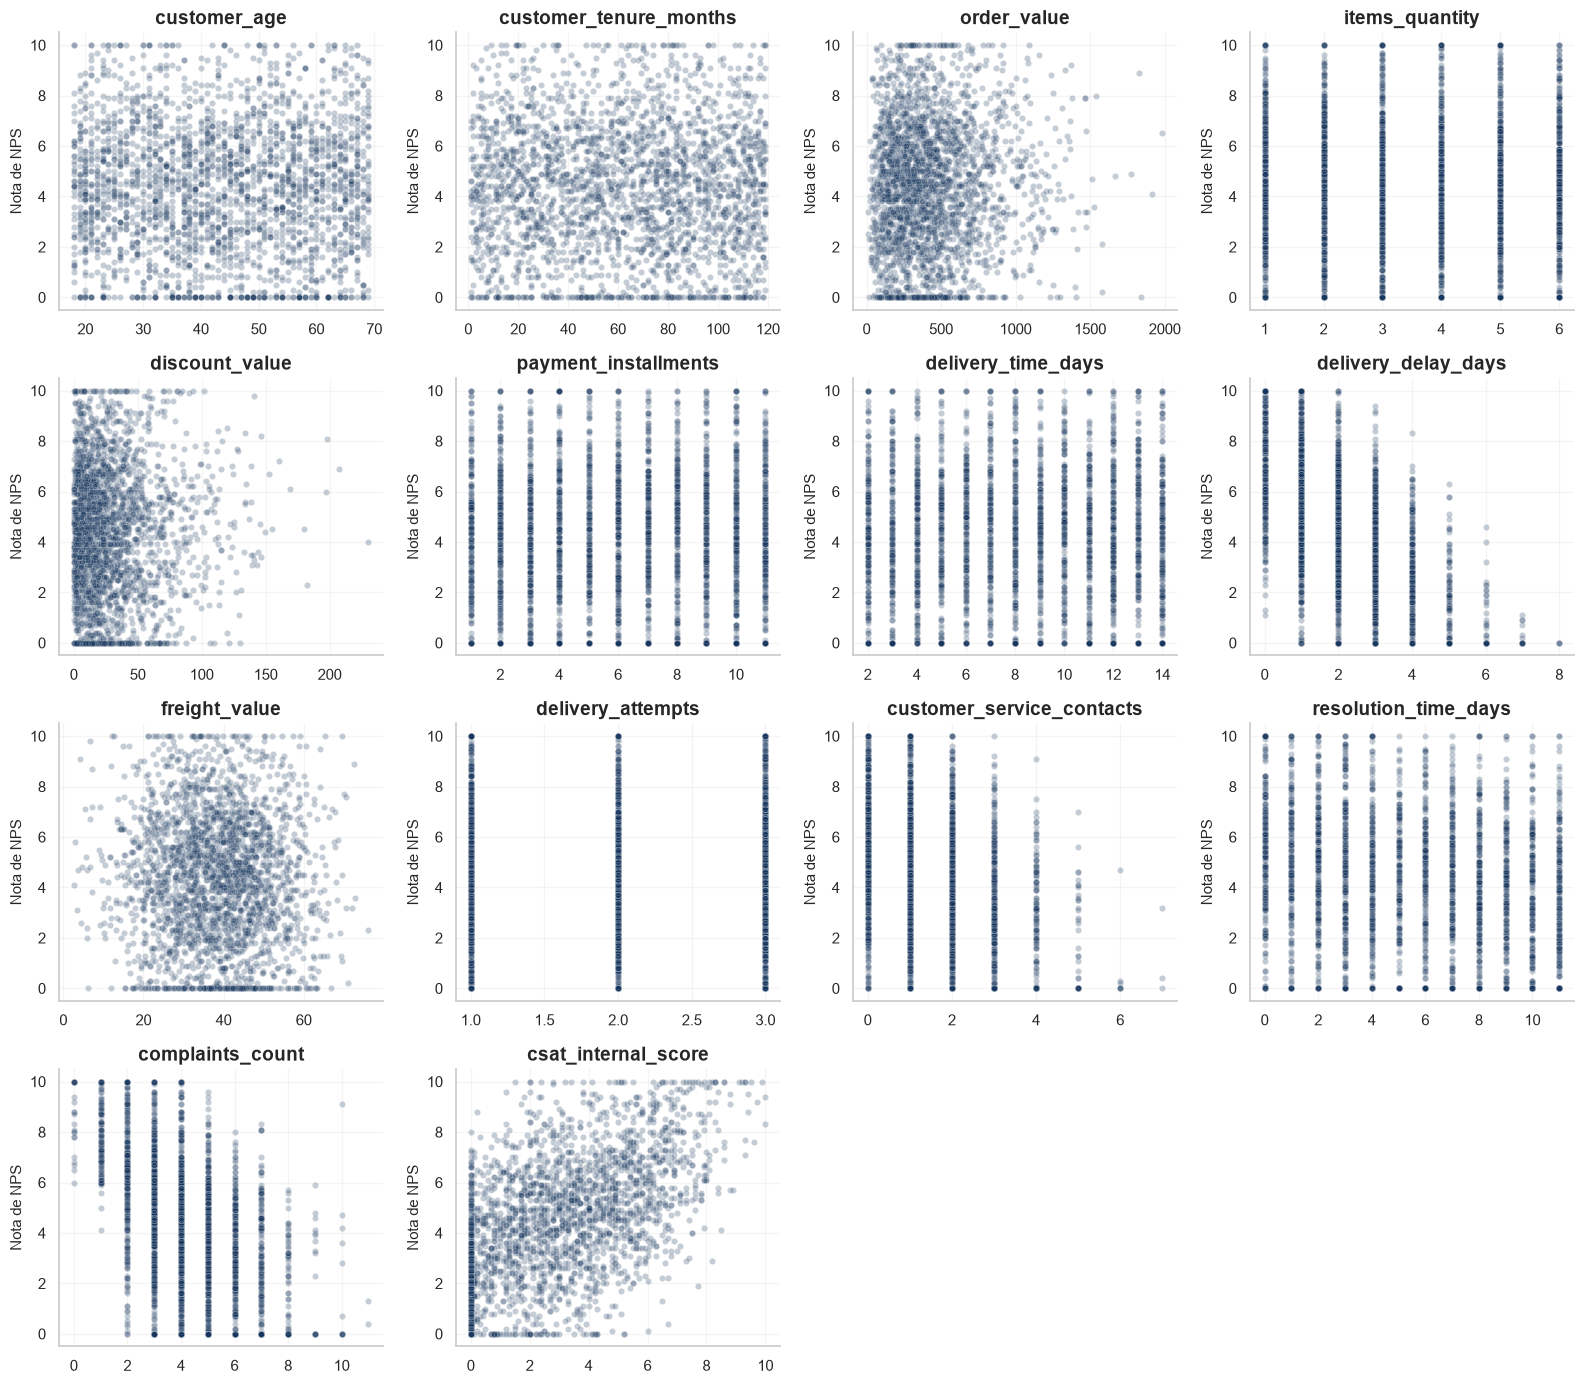

In [72]:
# Selecionar variáveis numéricas
variaveis = dados.select_dtypes(include="number").columns.drop([
    "customer_id",
    "order_id",
    "nps_score",
    "repeat_purchase_30d"
])

# Criar os gráficos de dispersão
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, coluna in zip(axes.flat, variaveis):
    sns.scatterplot(
        data=dados,
        x=coluna,
        y="nps_score",
        color=AZUL,
        alpha=0.25,
        s=20,
        ax=ax
    )

    ax.set_title(coluna)
    ax.set_xlabel("")
    ax.set_ylabel("Nota de NPS")
    ax.set_ylim(-0.5, 10.5)

# Ocultar gráficos sem variáveis
for ax in axes.flat[len(variaveis):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

**Análise dos gráficos de dispersão**

Os gráficos indicam possíveis relações negativas entre a nota de NPS e os dias de atraso, a quantidade de reclamações e os contatos com atendimento.

Também foi observada uma tendência positiva entre o NPS e o indicador interno de satisfação (`csat_internal_score`).

Nas demais variáveis, não foram identificadas tendências visuais claras. Por isso, vamos utilizar a análise de correlação para avaliar melhor a intensidade dessas relações.

### 7.2 Análise de Correlação

Após a análise de dispersão, foi utilizada a correlação de Spearman para avaliar a direção e a intensidade das associações entre os indicadores operacionais e o NPS.

O heatmap permite visualizar tanto a relação do NPS com os demais indicadores quanto as correlações entre as próprias variáveis analisadas.

Essa etapa ajuda a identificar quais fatores merecem maior aprofundamento nas próximas análises, sem representar, por si só, uma relação de causa e efeito.

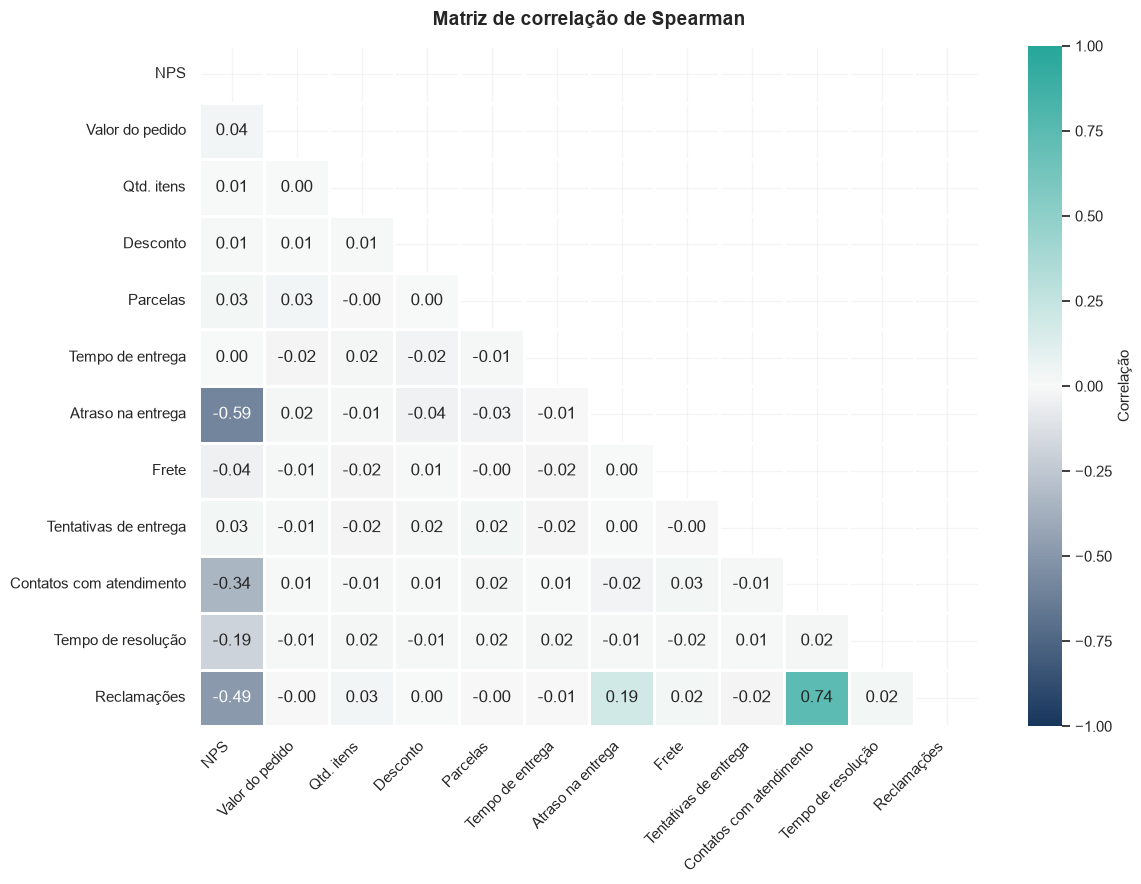

In [73]:
# Variáveis da análise
variaveis = [
    "nps_score",
    "order_value",
    "items_quantity",
    "discount_value",
    "payment_installments",
    "delivery_time_days",
    "delivery_delay_days",
    "freight_value",
    "delivery_attempts",
    "customer_service_contacts",
    "resolution_time_days",
    "complaints_count"
]

# Renomear para ficar mais legível no gráfico
nomes = {
    "nps_score": "NPS",
    "order_value": "Valor do pedido",
    "items_quantity": "Qtd. itens",
    "discount_value": "Desconto",
    "payment_installments": "Parcelas",
    "delivery_time_days": "Tempo de entrega",
    "delivery_delay_days": "Atraso na entrega",
    "freight_value": "Frete",
    "delivery_attempts": "Tentativas de entrega",
    "customer_service_contacts": "Contatos com atendimento",
    "resolution_time_days": "Tempo de resolução",
    "complaints_count": "Reclamações"
}

# Base somente com as variáveis escolhidas
base_corr = dados[variaveis].rename(columns=nomes)

# Correlação de Spearman
corr = base_corr.corr(method="spearman")

# Máscara para ocultar o triângulo superior
mask = np.triu(np.ones_like(corr, dtype=bool))

# Paleta divergente seguindo nosso padrão visual
cores = LinearSegmentedColormap.from_list(
    "cor_nps",
    [AZUL, "#F8F8F8", VERDE]
)

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap=cores,
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Correlação"}
)

plt.title("Matriz de correlação de Spearman", pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

**Referência para interpretação dos coeficientes de correlação**

| Valor absoluto da correlação (\|r\|) | Intensidade |
|:---:|---|
| 0,00 a 0,19 | Muito fraca ou ausente |
| 0,20 a 0,39 | Fraca |
| 0,40 a 0,69 | Moderada |
| 0,70 a 0,89 | Forte |
| 0,90 a 1,00 | Muito forte |


**Resumo da análise de correlação**

O atraso na entrega apresentou a maior correlação negativa com o NPS (-0,59), seguido pela quantidade de reclamações (-0,49) e pelos contatos com atendimento (-0,34).

Também foi identificada uma forte correlação positiva entre reclamações e contatos com atendimento (0,74), indicando que esses problemas frequentemente aparecem associados.

Os demais indicadores operacionais apresentaram correlações próximas de zero, sugerindo menor associação monotônica com a satisfação dos clientes.

Esses resultados indicam que a logística e o atendimento devem ser priorizados nas próximas análises, buscando compreender melhor seu impacto na experiência dos clientes.

### 7.3 Análise dos Atrasos nas Entregas

O atraso nas entregas apresentou a maior correlação negativa com o NPS (-0,59), indicando uma associação relevante com a insatisfação dos clientes.

Nesta etapa, vamos investigar como a satisfação varia conforme os dias de atraso e verificar se existe algum ponto de ruptura na experiência.

**Pergunta:** A partir de quantos dias de atraso a satisfação dos clientes apresenta uma queda mais acentuada?

In [74]:
# Quantidade de pedidos e nota média por dias de atraso
nps_por_atraso = (
    dados.groupby("delivery_delay_days")["nps_score"]
    .agg(["count", "mean"])
    .reset_index()
)

# Renomear as colunas
nps_por_atraso.columns = [
    "Dias de atraso",
    "Quantidade de pedidos",
    "Nota média NPS"
]

display(nps_por_atraso.round(2))

,Dias de atraso,Quantidade de pedidos,Nota média NPS
0,0,277,6.86
1,1,615,5.55
2,2,646,4.58
3,3,525,3.44
4,4,270,2.44
5,5,116,1.48
6,6,34,1.10
7,7,14,0.29
8,8,3,0.00


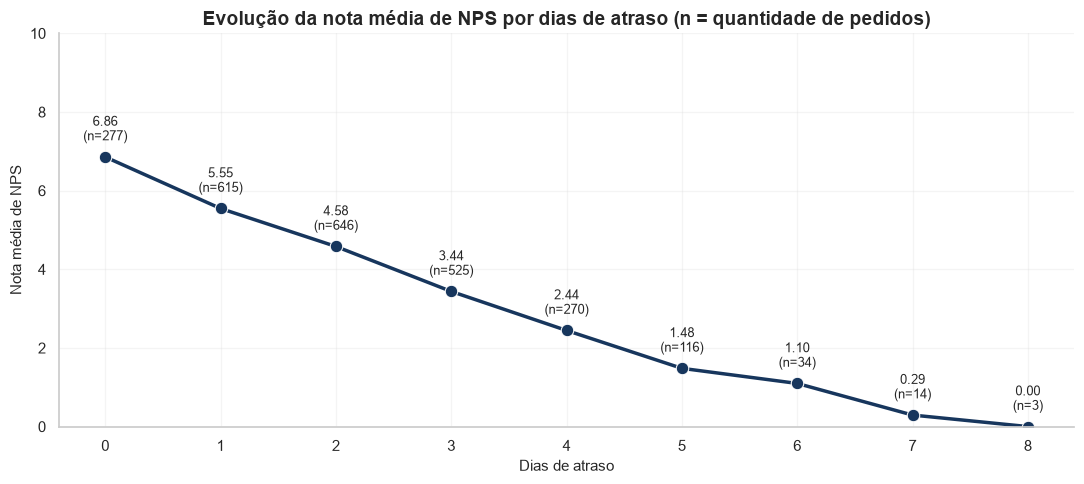

In [75]:
plt.figure(figsize=(11, 5))

ax = sns.lineplot(
    data=nps_por_atraso,
    x="Dias de atraso",
    y="Nota média NPS",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Exibir nota média e quantidade de pedidos
for _, linha in nps_por_atraso.iterrows():
    ax.annotate(
        f'{linha["Nota média NPS"]:.2f}\n(n={int(linha["Quantidade de pedidos"])})',
        (linha["Dias de atraso"], linha["Nota média NPS"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9
    )

plt.title("Evolução da nota média de NPS por dias de atraso (n = quantidade de pedidos)")
plt.xlabel("Dias de atraso")
plt.ylabel("Nota média de NPS")
plt.xticks(range(9))
plt.ylim(0, 10)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

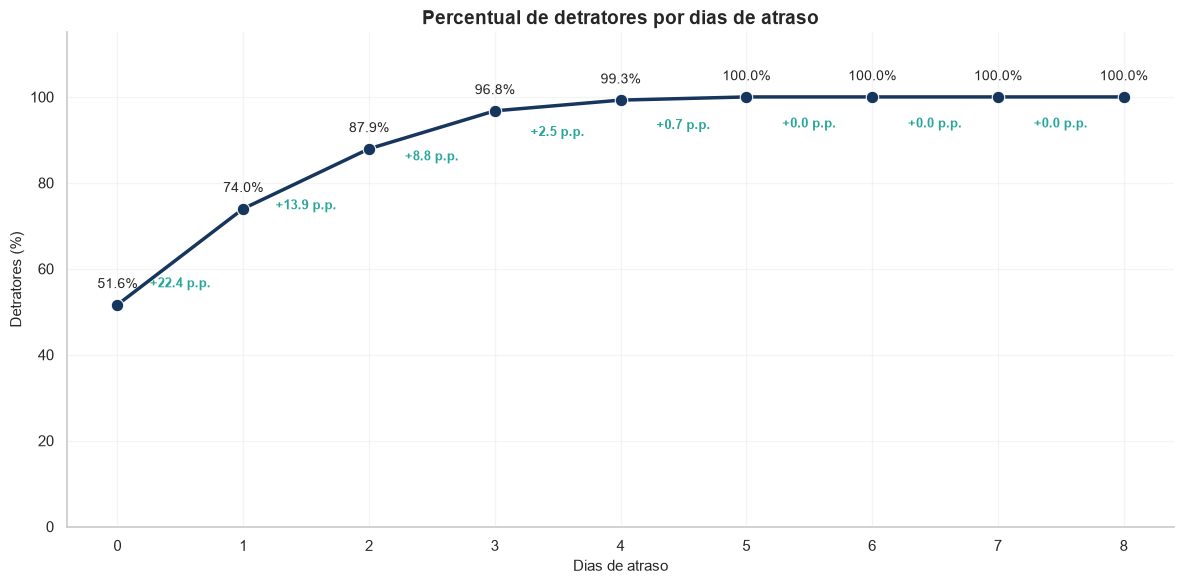

In [76]:
# Percentual de detratores por dias de atraso
detratores_atraso = (
    dados.groupby("delivery_delay_days")["nps_classificacao"]
    .apply(lambda x: (x == "Detrator").mean() * 100)
    .reset_index(name="Percentual de detratores")
)

# Variação em pontos percentuais entre os dias
detratores_atraso["Variação (p.p.)"] = (
    detratores_atraso["Percentual de detratores"].diff()
)

plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=detratores_atraso,
    x="delivery_delay_days",
    y="Percentual de detratores",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Percentual de detratores acima dos pontos
for _, linha in detratores_atraso.iterrows():
    ax.annotate(
        f'{linha["Percentual de detratores"]:.1f}%',
        (linha["delivery_delay_days"], linha["Percentual de detratores"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=10
    )

# Variação entre dias, abaixo de cada intervalo
for i in range(1, len(detratores_atraso)):
    anterior = detratores_atraso.iloc[i - 1]
    atual = detratores_atraso.iloc[i]

    x = (anterior["delivery_delay_days"] + atual["delivery_delay_days"]) / 2
    y = (anterior["Percentual de detratores"] + atual["Percentual de detratores"]) / 2

    ax.annotate(
        f'{atual["Variação (p.p.)"]:+.1f} p.p.',
        (x, y),
        textcoords="offset points",
        xytext=(0, -22),
        ha="center",
        fontsize=9,
        color=VERDE,
        fontweight="bold"
    )

plt.title("Percentual de detratores por dias de atraso")
plt.xlabel("Dias de atraso")
plt.ylabel("Detratores (%)")
plt.xticks(range(9))
plt.ylim(0, 115)

plt.tight_layout()
plt.show()

**Resumo da análise dos atrasos nas entregas**

O atraso nas entregas apresentou uma associação negativa moderada com a satisfação dos clientes, com correlação de Spearman de -0,59.

A nota média de NPS diminuiu progressivamente, passando de 6,86 nos pedidos sem atraso para 1,48 nos pedidos com 5 dias de atraso.

O maior aumento na proporção de detratores ocorreu já no primeiro dia de atraso, passando de 51,6% para 74,0%, uma diferença de 22,4 pontos percentuais.

Esses resultados indicam que mesmo pequenos atrasos estão associados a uma pior experiência, tornando o cumprimento dos prazos de entrega uma prioridade de investigação para a empresa.

### 7.4 Análise de Reclamações e Atendimento

Na análise de correlação, a quantidade de reclamações apresentou associação negativa moderada com o NPS (-0,49), enquanto os contatos com atendimento apresentaram associação negativa fraca (-0,34).

Também foi identificada uma correlação positiva forte (0,74) entre reclamações e contatos com atendimento.

Nesta etapa, vamos investigar como esses indicadores estão relacionados à satisfação dos clientes.

**Pergunta:** Como a quantidade de reclamações influencia a satisfação dos clientes?

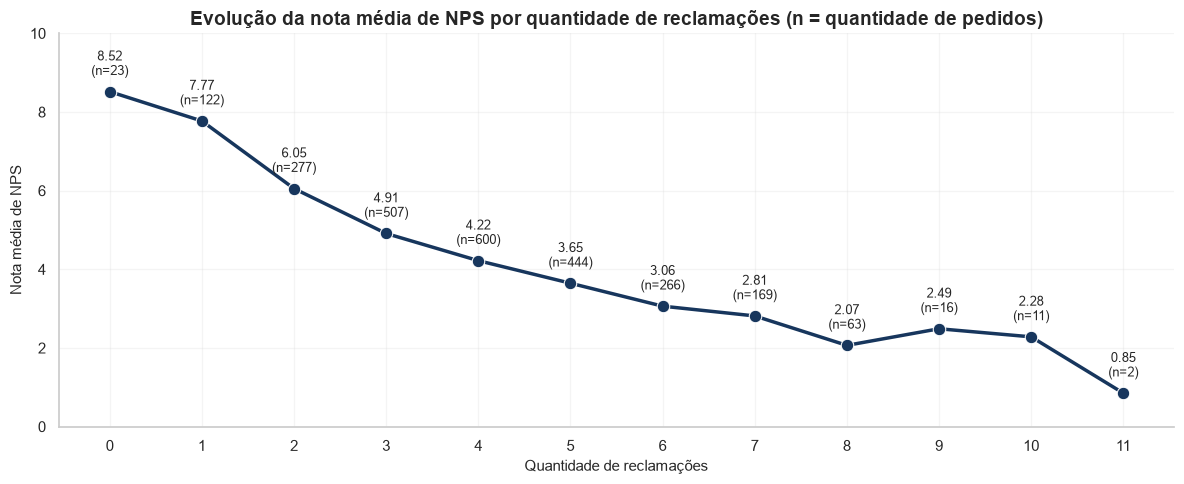

In [77]:
# Calcular a quantidade de pedidos e a nota média por reclamações
nps_por_reclamacoes = (
    dados.groupby("complaints_count")["nps_score"]
    .agg(["count", "mean"])
    .reset_index()
)

# Renomear as colunas
nps_por_reclamacoes.columns = [
    "Quantidade de reclamações",
    "Quantidade de pedidos",
    "Nota média NPS"
]

plt.figure(figsize=(12, 5))

ax = sns.lineplot(
    data=nps_por_reclamacoes,
    x="Quantidade de reclamações",
    y="Nota média NPS",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Exibir nota média e quantidade de pedidos
for _, linha in nps_por_reclamacoes.iterrows():
    ax.annotate(
        f'{linha["Nota média NPS"]:.2f}\n(n={int(linha["Quantidade de pedidos"])})',
        (linha["Quantidade de reclamações"], linha["Nota média NPS"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9
    )

plt.title("Evolução da nota média de NPS por quantidade de reclamações (n = quantidade de pedidos)")
plt.xlabel("Quantidade de reclamações")
plt.ylabel("Nota média de NPS")
plt.xticks(range(12))
plt.ylim(0, 10)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

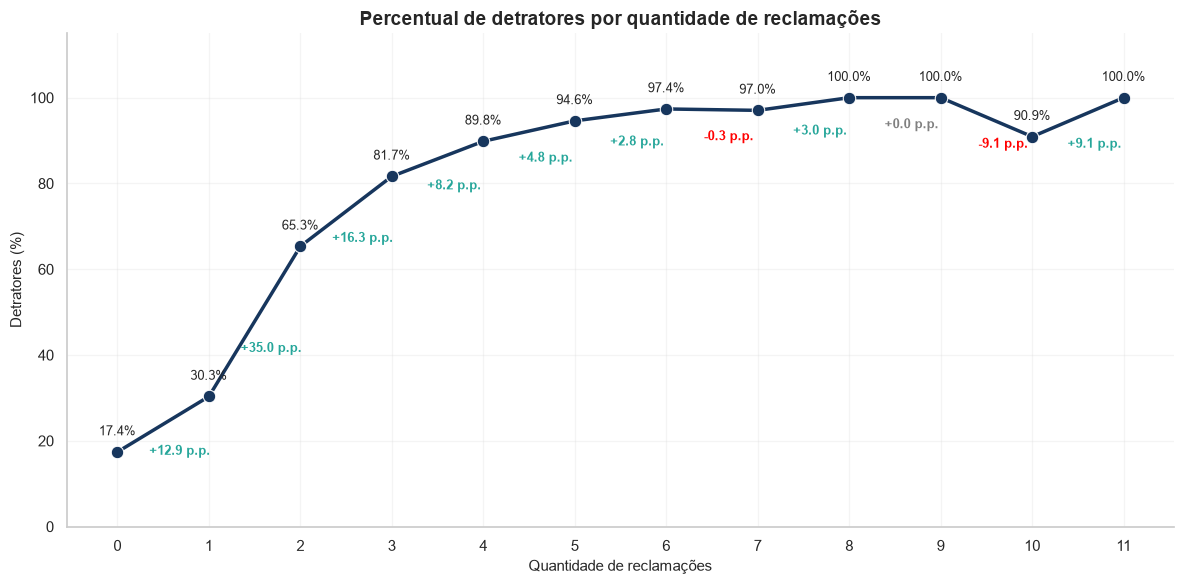

In [78]:
# Percentual de detratores por quantidade de reclamações
detratores_reclamacoes = (
    dados.groupby("complaints_count")["nps_classificacao"]
    .apply(lambda x: (x == "Detrator").mean() * 100)
    .reset_index(name="Percentual de detratores")
)

# Variação em pontos percentuais
detratores_reclamacoes["Variação (p.p.)"] = (
    detratores_reclamacoes["Percentual de detratores"].diff()
)

plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=detratores_reclamacoes,
    x="complaints_count",
    y="Percentual de detratores",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Exibir percentual de detratores
for _, linha in detratores_reclamacoes.iterrows():
    ax.annotate(
        f'{linha["Percentual de detratores"]:.1f}%',
        (linha["complaints_count"], linha["Percentual de detratores"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9
    )

# Exibir variação entre quantidades de reclamações
for i in range(1, len(detratores_reclamacoes)):
    anterior = detratores_reclamacoes.iloc[i - 1]
    atual = detratores_reclamacoes.iloc[i]

    x = (anterior["complaints_count"] + atual["complaints_count"]) / 2
    y = (anterior["Percentual de detratores"] + atual["Percentual de detratores"]) / 2

    variacao = atual["Variação (p.p.)"]

    if variacao > 0:
        cor = VERDE
    elif variacao < 0:
        cor = "red"
    else:
        cor = "gray"

    ax.annotate(
        f'{variacao:+.1f} p.p.',
        (x, y),
        textcoords="offset points",
        xytext=(12, -22),
        ha="center",
        fontsize=9,
        color=cor,
        fontweight="bold"
    )

plt.title("Percentual de detratores por quantidade de reclamações")
plt.xlabel("Quantidade de reclamações")
plt.ylabel("Detratores (%)")
plt.xticks(range(12))
plt.ylim(0, 115)

plt.tight_layout()
plt.show()

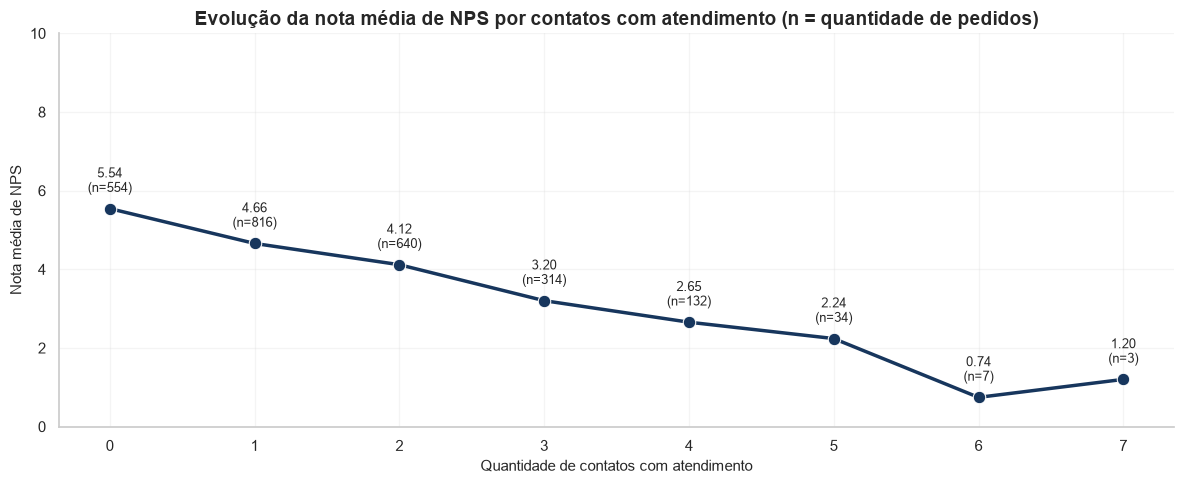

In [79]:
# Nota média de NPS por quantidade de contatos com atendimento
nps_por_contatos = (
    dados.groupby("customer_service_contacts")["nps_score"]
    .agg(["count", "mean"])
    .reset_index()
)

nps_por_contatos.columns = [
    "Quantidade de contatos",
    "Quantidade de pedidos",
    "Nota média NPS"
]

plt.figure(figsize=(12, 5))

ax = sns.lineplot(
    data=nps_por_contatos,
    x="Quantidade de contatos",
    y="Nota média NPS",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Exibir nota média e quantidade de pedidos
for _, linha in nps_por_contatos.iterrows():
    ax.annotate(
        f'{linha["Nota média NPS"]:.2f}\n(n={int(linha["Quantidade de pedidos"])})',
        (linha["Quantidade de contatos"], linha["Nota média NPS"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9
    )

plt.title("Evolução da nota média de NPS por contatos com atendimento (n = quantidade de pedidos)")
plt.xlabel("Quantidade de contatos com atendimento")
plt.ylabel("Nota média de NPS")
plt.xticks(nps_por_contatos["Quantidade de contatos"])
plt.ylim(0, 10)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

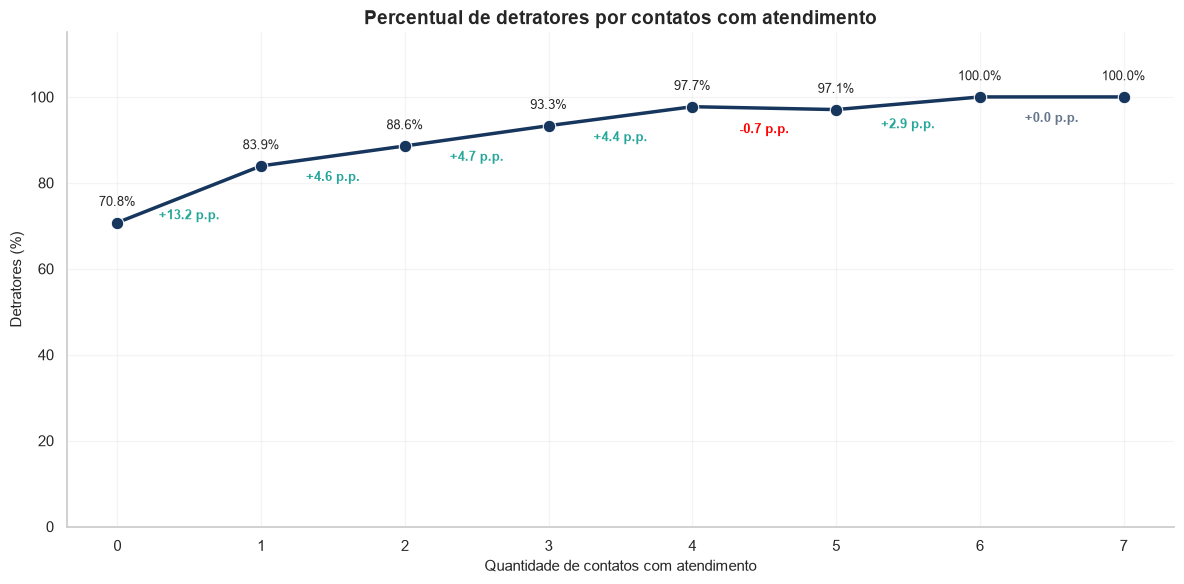

In [80]:
# Percentual de detratores por quantidade de contatos
detratores_contatos = (
    dados.groupby("customer_service_contacts")["nps_classificacao"]
    .apply(lambda x: (x == "Detrator").mean() * 100)
    .reset_index(name="Percentual de detratores")
)

# Variação em pontos percentuais
detratores_contatos["Variação (p.p.)"] = (
    detratores_contatos["Percentual de detratores"].diff()
)

plt.figure(figsize=(12, 6))

ax = sns.lineplot(
    data=detratores_contatos,
    x="customer_service_contacts",
    y="Percentual de detratores",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Percentuais acima dos pontos
for _, linha in detratores_contatos.iterrows():
    ax.annotate(
        f'{linha["Percentual de detratores"]:.1f}%',
        (linha["customer_service_contacts"], linha["Percentual de detratores"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9
    )

# Variação entre quantidades de contatos
for i in range(1, len(detratores_contatos)):
    anterior = detratores_contatos.iloc[i - 1]
    atual = detratores_contatos.iloc[i]

    x = (anterior["customer_service_contacts"] + atual["customer_service_contacts"]) / 2
    y = (anterior["Percentual de detratores"] + atual["Percentual de detratores"]) / 2

    variacao = atual["Variação (p.p.)"]

    if variacao > 0:
        cor = VERDE
    elif variacao < 0:
        cor = "red"
    else:
        cor = CINZA

    ax.annotate(
        f"{variacao:+.1f} p.p.",
        (x, y),
        textcoords="offset points",
        xytext=(0, -18),
        ha="center",
        fontsize=9,
        color=cor,
        fontweight="bold"
    )

plt.title("Percentual de detratores por contatos com atendimento")
plt.xlabel("Quantidade de contatos com atendimento")
plt.ylabel("Detratores (%)")
plt.xticks(detratores_contatos["customer_service_contacts"])
plt.ylim(0, 115)

plt.tight_layout()
plt.show()

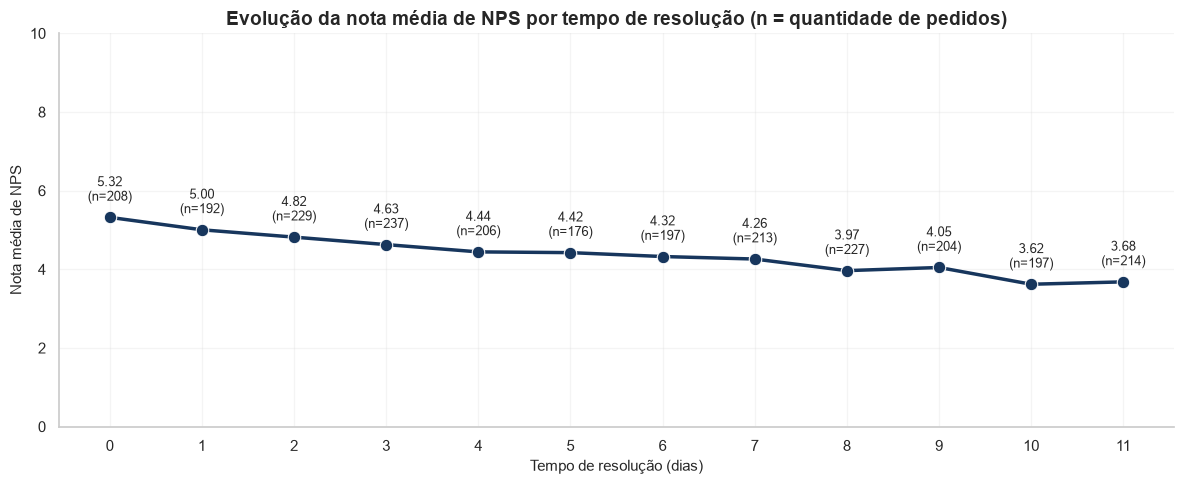

In [82]:
# Nota média de NPS por tempo de resolução
nps_por_resolucao = (
    dados.groupby("resolution_time_days")["nps_score"]
    .agg(["count", "mean"])
    .reset_index()
)

nps_por_resolucao.columns = [
    "Dias para resolução",
    "Quantidade de pedidos",
    "Nota média NPS"
]

plt.figure(figsize=(12, 5))

ax = sns.lineplot(
    data=nps_por_resolucao,
    x="Dias para resolução",
    y="Nota média NPS",
    marker="o",
    markersize=9,
    linewidth=2.5,
    color=AZUL
)

# Exibir nota média e quantidade de pedidos
for _, linha in nps_por_resolucao.iterrows():
    ax.annotate(
        f'{linha["Nota média NPS"]:.2f}\n(n={int(linha["Quantidade de pedidos"])})',
        (linha["Dias para resolução"], linha["Nota média NPS"]),
        textcoords="offset points",
        xytext=(0, 12),
        ha="center",
        fontsize=9
    )

plt.title("Evolução da nota média de NPS por tempo de resolução (n = quantidade de pedidos)")
plt.xlabel("Tempo de resolução (dias)")
plt.ylabel("Nota média de NPS")
plt.xticks(range(12))
plt.ylim(0, 10)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

**Resumo da análise de reclamações e atendimento**

A quantidade de reclamações apresentou associação negativa moderada com o NPS (-0,49), enquanto os contatos com atendimento apresentaram associação negativa fraca (-0,34).

O principal destaque ocorreu na passagem de 1 para 2 reclamações, quando o percentual de detratores aumentou de 30,3% para 65,3%, indicando um possível ponto crítico na experiência dos clientes.

Nos contatos com atendimento, o maior aumento ocorreu entre 0 e 1 contato, passando de 70,8% para 83,9% de detratores.

Já o tempo de resolução apresentou associação negativa muito fraca (-0,19), com redução gradual da nota média de 5,32 para 3,68 entre 0 e 11 dias.

Os resultados indicam que a quantidade de reclamações e a recorrência de contatos com atendimento merecem maior atenção, enquanto o tempo de resolução apresentou uma relação menos expressiva com a satisfação.

### 7.5 Comparação dos Detratores

Nesta etapa, vamos comparar os principais indicadores operacionais entre detratores, neutros e promotores, buscando identificar quais características diferenciam os clientes insatisfeitos dos demais.

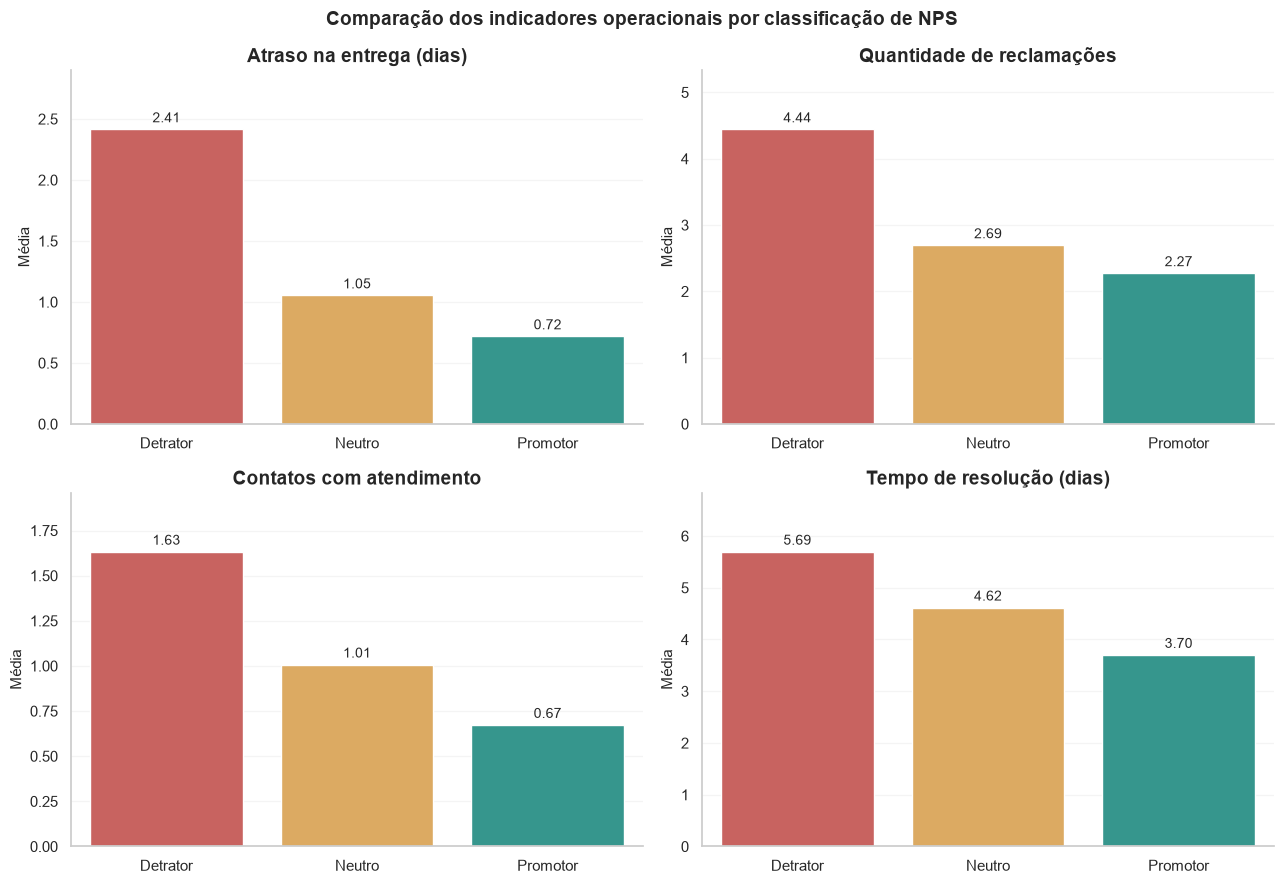

In [84]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

cores_nps = ["#D9534F", "#F0AD4E", VERDE]

for ax, coluna in zip(axes.flat, comparacao_nps.columns):

    sns.barplot(
        x=comparacao_nps.index,
        y=comparacao_nps[coluna],
        hue=comparacao_nps.index,
        palette=cores_nps,
        legend=False,
        ax=ax
    )

    for barras in ax.containers:
        ax.bar_label(
            barras,
            fmt="%.2f",
            padding=3,
            fontsize=10
        )

    ax.set_title(coluna)
    ax.set_xlabel("")
    ax.set_ylabel("Média")
    ax.set_ylim(0, comparacao_nps[coluna].max() * 1.2)

plt.suptitle(
    "Comparação dos indicadores operacionais por classificação de NPS",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Resumo da comparação dos detratores**

Os clientes classificados como detratores apresentaram, em média, mais atrasos nas entregas, reclamações, contatos com atendimento e maior tempo de resolução do que os clientes neutros e promotores.

A diferença é especialmente evidente nos atrasos, com média de 2,41 dias entre detratores, contra 0,72 dia entre promotores. Também se destaca a quantidade de reclamações, com médias de 4,44 e 2,27, respectivamente.

Esses resultados reforçam que experiências negativas relacionadas à logística e ao atendimento estão associadas à insatisfação dos clientes.

### 7.6 Síntese dos Fatores Operacionais

A análise identificou que **atrasos nas entregas, reclamações e contatos com atendimento** são os indicadores operacionais mais associados à insatisfação dos clientes.

**Principais resultados:**

- **Atrasos nas entregas:** apresentaram a maior correlação negativa com o NPS (-0,59). Já no primeiro dia de atraso, o percentual de detratores aumentou de 51,6% para 74,0%.
- **Reclamações:** apresentaram correlação negativa moderada (-0,49). O maior aumento de detratores ocorreu entre 1 e 2 reclamações, passando de 30,3% para 65,3%.
- **Contatos com atendimento:** apresentaram correlação negativa fraca (-0,34). A proporção de detratores aumentou de 70,8% para 83,9% entre clientes com zero e um contato.
- **Tempo de resolução:** apresentou correlação negativa muito fraca (-0,19), com redução gradual da satisfação e sem ponto de ruptura evidente.

A comparação entre os grupos de NPS confirmou que os detratores apresentam, em média, mais atrasos, reclamações, contatos com atendimento e maior tempo de resolução do que os promotores.

## 8. Conclusões e Recomendações de Negócio

Nesta etapa, serão consolidados os principais resultados da análise exploratória, com o objetivo de identificar oportunidades de melhoria na experiência dos clientes e apoiar a tomada de decisão.

### 8.1 Principais Achados

A análise revelou um cenário de insatisfação generalizada, com **NPS agregado de -80**, sendo 84,4% dos clientes classificados como detratores.

Em relação ao perfil dos clientes, foram observadas diferenças relativamente pequenas entre as regiões. A faixa etária de **40 a 49 anos** apresentou o pior NPS (-84,3), enquanto os clientes com **3 a 5 anos de relacionamento** também se destacaram negativamente (-83,3).

Entre os indicadores operacionais, os principais fatores associados à insatisfação foram:

- **Atrasos nas entregas:** maior correlação negativa com o NPS (-0,59), com aumento expressivo de detratores já no primeiro dia de atraso.
- **Reclamações:** correlação negativa de -0,49, com destaque para a passagem de uma para duas reclamações, quando a proporção de detratores ultrapassou 65%.
- **Contatos com atendimento:** correlação negativa de -0,34, indicando menor satisfação entre clientes com maior necessidade de contato.
- **Tempo de resolução:** correlação negativa de -0,19, apresentando associação menos expressiva.

Os resultados sugerem que os problemas relacionados à **logística e ao atendimento** estão mais associados à insatisfação do que as características demográficas analisadas.

### 8.2 Recomendações de Negócio

Com base nos resultados encontrados, foram identificadas oportunidades de melhoria na logística e no atendimento ao cliente.

**1. Reduzir os atrasos nas entregas**

O atraso apresentou a maior correlação negativa com o NPS (-0,59). Já no primeiro dia de atraso, a proporção de detratores passou de 51,6% para 74,0%.

**Recomendação:** priorizar o cumprimento dos prazos de entrega, monitorar pedidos com risco de atraso e comunicar antecipadamente possíveis problemas aos clientes.

**2. Reduzir a recorrência de reclamações**

A passagem de uma para duas reclamações apresentou o maior aumento na proporção de detratores, de 30,3% para 65,3%.

**Recomendação:** investigar as principais causas das reclamações e atuar para evitar sua repetição, especialmente após o primeiro registro.

**3. Melhorar a efetividade do atendimento**

Clientes com mais contatos apresentaram menor satisfação, e reclamações e contatos com atendimento tiveram correlação positiva forte (0,74).

**Recomendação:** buscar soluções mais efetivas nos primeiros contatos e acompanhar casos recorrentes, reduzindo a necessidade de novas interações pelo mesmo problema.

**4. Investigar os segmentos com maior insatisfação**

Os clientes de 40 a 49 anos e aqueles com 3 a 5 anos de relacionamento apresentaram os menores indicadores de NPS em suas respectivas segmentações.

**Recomendação:** investigar se esses grupos enfrentam problemas operacionais específicos, antes de desenvolver ações direcionadas.

**Priorização:** as primeiras ações devem concentrar-se na redução dos atrasos e na prevenção de reclamações recorrentes, por serem os fatores que apresentaram as associações mais relevantes com a insatisfação.